**Laboratory Assignment 8: High Performance Big Data Analytics Using R**

**Problem statement**

The NYC Taxi and Limousine Commission records millions of taxi trips. Normal ways of processing this much data in R can be slow and use a lot of memory. In this lab I analyse the yellow taxi data with data.table, compare it with functional (apply, lapply, purrr) and vectorized code, run one heavy job sequentially and in parallel with foreach and doParallel, and benchmark everything to decide which approach is best for large data.

**Dataset**

NYC TLC Yellow Taxi Trip Records for January, February and March 2023 (about 9.4 million raw trips) and the Taxi Zone Lookup table. Source: https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page

Columns used: pickup and dropoff time, pickup and dropoff location ID, passenger count, trip distance, payment type, fare, tip, tolls and total amount. The files are downloaded inside the notebook, so nothing has to be uploaded. If the download is blocked, download the three parquet files and the zone csv from the TLC page and upload them to the Colab session with the same file names.

**Setup**

In [1]:
pkgs <- c("data.table", "ggplot2", "foreach", "doParallel", "microbenchmark", "purrr", "nanoparquet")
new <- pkgs[!pkgs %in% rownames(installed.packages())]
if (length(new)) install.packages(new)

library(data.table)
library(ggplot2)
library(foreach)
library(doParallel)
library(microbenchmark)

set.seed(42)
options(repr.plot.width = 9, repr.plot.height = 5)
cat("data.table threads:", getDTthreads(), "| cores on this machine:", detectCores(), "\n")

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘iterators’



Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%


Loading required package: iterators

Loading required package: parallel



data.table threads: 1 | cores on this machine: 2 


**Task 1: Data acquisition and preparation**

Three months are read from the official parquet files and stacked into one data.table. Only the columns needed for the analysis are kept right after reading, so the other columns never sit in memory.

In [2]:
months <- sprintf("2023-%02d", 1:3)
base_url <- "https://d37ci6vzurychx.cloudfront.net/trip-data/"
keep_cols <- c("tpep_pickup_datetime", "tpep_dropoff_datetime", "passenger_count",
               "trip_distance", "PULocationID", "DOLocationID", "payment_type",
               "fare_amount", "tip_amount", "tolls_amount", "total_amount")

read_month <- function(m) {
  f <- paste0("yellow_tripdata_", m, ".parquet")
  if (!file.exists(f)) download.file(paste0(base_url, f), f, mode = "wb", quiet = TRUE)
  d <- as.data.table(nanoparquet::read_parquet(f))
  d[, ..keep_cols]
}
trips <- rbindlist(lapply(months, read_month))

# taxi zone lookup table
zone_file <- "taxi_zone_lookup.csv"
if (!file.exists(zone_file)) {
  download.file("https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv", zone_file, mode = "wb", quiet = TRUE)
}
zones <- fread(zone_file)

In [3]:
# structure, size and summary of the raw data
dim(trips)
str(trips)
summary(trips)
sapply(trips, function(x) sum(is.na(x)))     # missing values per column
print(object.size(trips), units = "MB")
dim(zones)
head(zones)

[1] 9384487      11

Classes ‘data.table’ and 'data.frame':	9384487 obs. of  11 variables:
 $ tpep_pickup_datetime : POSIXct, format: "2023-01-01 00:32:10" "2023-01-01 00:55:08" ...
 $ tpep_dropoff_datetime: POSIXct, format: "2023-01-01 00:40:36" "2023-01-01 01:01:27" ...
 $ passenger_count      : num  1 1 1 0 1 1 1 1 1 1 ...
 $ trip_distance        : num  0.97 1.1 2.51 1.9 1.43 1.84 1.66 11.7 2.95 3.01 ...
 $ PULocationID         : num  161 43 48 138 107 161 239 142 164 141 ...
 $ DOLocationID         : num  141 237 238 7 79 137 143 200 236 107 ...
 $ payment_type         : num  2 1 1 1 1 1 1 1 1 2 ...
 $ fare_amount          : num  9.3 7.9 14.9 12.1 11.4 12.8 12.1 45.7 17.7 14.9 ...
 $ tip_amount           : num  0 4 15 0 3.28 ...
 $ tolls_amount         : num  0 0 0 0 0 0 0 3 0 0 ...
 $ total_amount         : num  14.3 16.9 34.9 20.9 19.7 ...
 - attr(*, ".internal.selfref")=<pointer: 0x5a47ad1ad3f0> 


 tpep_pickup_datetime          tpep_dropoff_datetime         passenger_count 
 Min.   :2001-01-01 00:06:49   Min.   :2001-01-01 14:13:51   Min.   :0.000   
 1st Qu.:2023-01-24 23:33:22   1st Qu.:2023-01-24 23:48:47   1st Qu.:1.000   
 Median :2023-02-16 14:58:37   Median :2023-02-16 15:17:08   Median :1.000   
 Mean   :2023-02-16 05:29:55   Mean   :2023-02-16 05:46:08   Mean   :1.355   
 3rd Qu.:2023-03-10 14:34:35   3rd Qu.:2023-03-10 14:54:20   3rd Qu.:1.000   
 Max.   :2023-04-05 20:17:42   Max.   :2023-04-05 20:35:28   Max.   :9.000   
                                                             NAs    :236179  
 trip_distance       PULocationID  DOLocationID    payment_type  
 Min.   :0.00e+00   Min.   :  1   Min.   :  1.0   Min.   :0.000  
 1st Qu.:1.06e+00   1st Qu.:132   1st Qu.:114.0   1st Qu.:1.000  
 Median :1.79e+00   Median :162   Median :162.0   Median :1.000  
 Mean   :3.87e+00   Mean   :166   Mean   :164.2   Mean   :1.188  
 3rd Qu.:3.33e+00   3rd Qu.:234   3rd Qu.:234.

tpep_pickup_datetime tpep_dropoff_datetime       passenger_count 
                    0                     0                236179 
        trip_distance          PULocationID          DOLocationID 
                    0                     0                     0 
         payment_type           fare_amount            tip_amount 
                    0                     0                     0 
         tolls_amount          total_amount 
                    0                     0

787.6 Mb


[1] 265   4

LocationID,Borough,Zone,service_zone
<int>,<chr>,<chr>,<chr>
1,EWR,Newark Airport,EWR
2,Queens,Jamaica Bay,Boro Zone
3,Bronx,Allerton/Pelham Gardens,Boro Zone
4,Manhattan,Alphabet City,Yellow Zone
5,Staten Island,Arden Heights,Boro Zone
6,Staten Island,Arrochar/Fort Wadsworth,Boro Zone


In [4]:
# duplicates
n_dup <- sum(duplicated(trips))
cat("duplicate rows:", n_dup, "\n")
trips <- unique(trips)

duplicate rows: 0 


In [5]:
# data types: counts and ids as integer, payment type as a labelled factor
trips[, `:=`(passenger_count = as.integer(passenger_count),
             PULocationID = as.integer(PULocationID),
             DOLocationID = as.integer(DOLocationID))]
trips[, payment := factor(payment_type, levels = 0:6,
      labels = c("Unknown/Flex", "Credit card", "Cash", "No charge", "Dispute", "Unknown", "Voided"))]
trips[, payment_type := NULL]

# trip duration in minutes, needed for checking bad records
trips[, duration_min := as.numeric(difftime(tpep_dropoff_datetime, tpep_pickup_datetime, units = "mins"))]

In [6]:
# how many rows break each validity rule (one row can break more than one)
start <- as.POSIXct("2023-01-01", tz = "UTC")
end   <- as.POSIXct("2023-04-01", tz = "UTC")

invalid_report <- trips[, .(
  fare_not_positive         = sum(fare_amount <= 0),
  total_not_positive        = sum(total_amount <= 0),
  distance_zero_or_negative = sum(trip_distance <= 0),
  distance_over_100_miles   = sum(trip_distance > 100),
  passengers_missing_or_odd = sum(is.na(passenger_count) | passenger_count < 1 | passenger_count > 6),
  duration_under_1_or_over_6h = sum(duration_min <= 1 | duration_min > 360),
  pickup_outside_jan_mar_2023 = sum(tpep_pickup_datetime < start | tpep_pickup_datetime >= end)
)]
t(invalid_report)

fare_not_positive,82873
total_not_positive,81601
distance_zero_or_negative,135488
distance_over_100_miles,297
passengers_missing_or_odd,393040
duration_under_1_or_over_6h,113259
pickup_outside_jan_mar_2023,139


In [7]:
# remove the invalid records
n_before <- nrow(trips)
trips <- trips[fare_amount > 0 & fare_amount < 500 & total_amount > 0 &
               trip_distance > 0 & trip_distance <= 100 &
               !is.na(passenger_count) & passenger_count >= 1 & passenger_count <= 6 &
               duration_min > 1 & duration_min <= 360 &
               trip_distance / (duration_min / 60) <= 100 &      # more than 100 mph is not realistic
               tpep_pickup_datetime >= start & tpep_pickup_datetime < end]
cat("rows before:", n_before, "| after:", nrow(trips), "| removed:", n_before - nrow(trips),
    "(", round(100 * (n_before - nrow(trips)) / n_before, 2), "% )\n")

rows before: 9384487 | after: 8771965 | removed: 612522 ( 6.53 % )


In [8]:
# time features. TLC stores local New York time, so hour() on it gives the local hour
trips[, `:=`(hour = hour(tpep_pickup_datetime),
             day = mday(tpep_pickup_datetime),
             wday_num = wday(tpep_pickup_datetime),
             month = month(tpep_pickup_datetime))]
trips[, wday := factor(wday_num, levels = 1:7, labels = c("Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"))]

# drop columns that are not needed any more to save memory
trips[, c("tpep_pickup_datetime", "tpep_dropoff_datetime", "wday_num") := NULL]
invisible(gc())
print(object.size(trips), units = "MB")

669.3 Mb


In [9]:
# join with the zone table, once for pickup and once for dropoff (update join, no copy of trips)
zones <- zones[, .(LocationID, Borough, Zone)]
trips[zones, on = .(PULocationID = LocationID), `:=`(PU_borough = i.Borough, PU_zone = i.Zone)]
trips[zones, on = .(DOLocationID = LocationID), `:=`(DO_borough = i.Borough, DO_zone = i.Zone)]

trips[, .(pickup_unmatched = sum(is.na(PU_zone)), dropoff_unmatched = sum(is.na(DO_zone)))]
head(trips)

pickup_unmatched,dropoff_unmatched
<int>,<int>
0,0


passenger_count,trip_distance,PULocationID,DOLocationID,fare_amount,tip_amount,tolls_amount,total_amount,payment,duration_min,hour,day,month,wday,PU_borough,PU_zone,DO_borough,DO_zone
<int>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<dbl>,<int>,<int>,<int>,<fct>,<chr>,<chr>,<chr>,<chr>
1,0.97,161,141,9.3,0.00,0,14.30,Cash,8.433333,0,1,1,Sun,Manhattan,Midtown Center,Manhattan,Lenox Hill West
1,1.10,43,237,7.9,4.00,0,16.90,Credit card,6.316667,0,1,1,Sun,Manhattan,Central Park,Manhattan,Upper East Side South
1,2.51,48,238,14.9,15.00,0,34.90,Credit card,12.750000,0,1,1,Sun,Manhattan,Clinton East,Manhattan,Upper West Side North
1,1.43,107,79,11.4,3.28,0,19.68,Credit card,10.833333,0,1,1,Sun,Manhattan,Gramercy,Manhattan,East Village
1,1.84,161,137,12.8,10.00,0,27.80,Credit card,12.300000,0,1,1,Sun,Manhattan,Midtown Center,Manhattan,Kips Bay
1,1.66,239,143,12.1,3.42,0,20.52,Credit card,10.450000,0,1,1,Sun,Manhattan,Upper West Side South,Manhattan,Lincoln Square West


**Task 2: Transportation data analytics**

All of this is done with data.table grouping. Each result is stored in an object so it can be reused for plots later.

In [10]:
# 1 and 4. trips, average fare and revenue by hour of day
by_hour <- trips[, .(trips = .N, avg_fare = mean(fare_amount), revenue = sum(total_amount)), keyby = hour]
by_hour

hour,trips,avg_fare,revenue
<int>,<int>,<dbl>,<dbl>
0,237075,19.63974,6803257
1,159180,17.77168,4178778
2,103572,16.69605,2570651
3,70431,17.74865,1836239
4,44783,22.84133,1453150
5,47389,27.00867,1785700
6,120231,22.61288,3763724
7,240795,18.95813,6492862
8,332463,17.55556,8425864


In [11]:
# 2 and 4. demand by day of week
by_wday <- trips[, .(trips = .N, avg_fare = mean(fare_amount), revenue = sum(total_amount)), keyby = wday]
by_wday

wday,trips,avg_fare,revenue
<fct>,<int>,<dbl>,<dbl>
Sun,1102412,19.80830,31471942
Mon,1067830,19.54416,30763420
Tue,1249607,18.40047,34292163
Wed,1335135,18.47833,36821447
Thu,1400226,18.73605,39062374
Fri,1369951,18.48235,37831329
Sat,1246804,17.67399,32050568


In [12]:
# 3 and 4. monthly variation
by_month <- trips[, .(trips = .N, avg_fare = mean(fare_amount), revenue = sum(total_amount)), keyby = month]
by_month

# 4. average fare and revenue for broader parts of the day
by_period <- trips[, .(trips = .N, avg_fare = mean(fare_amount), revenue = sum(total_amount)),
                   by = .(period = fcase(hour >= 5 & hour < 12, "Morning (5-11)",
                                         hour >= 12 & hour < 17, "Afternoon (12-16)",
                                         hour >= 17 & hour < 22, "Evening (17-21)",
                                         default = "Night (22-4)"))][order(-trips)]
by_period

month,trips,avg_fare,revenue
<int>,<int>,<dbl>,<dbl>
1,2872830,18.50888,78506303
2,2721823,18.40972,74221873
3,3177312,19.09820,89565068


period,trips,avg_fare,revenue
<chr>,<int>,<dbl>,<dbl>
Evening (17-21),2774109,17.93908,76705033
Afternoon (12-16),2621749,19.34861,73541998
Morning (5-11),1968115,18.46135,52152144
Night (22-4),1407992,19.27254,39894069


In [13]:
# 5 and 6. routes (pickup zone to dropoff zone)
routes <- trips[!is.na(PU_zone) & !is.na(DO_zone),
                .(trips = .N, revenue = sum(total_amount), avg_fare = mean(fare_amount)),
                by = .(PU_zone, DO_zone)]
top_routes_count   <- routes[order(-trips)][1:10]
top_routes_revenue <- routes[order(-revenue)][1:10]
top_routes_count
top_routes_revenue

PU_zone,DO_zone,trips,revenue,avg_fare
<chr>,<chr>,<int>,<dbl>,<dbl>
Upper East Side South,Upper East Side North,61241,944574.3,8.643664
N/A,N/A,54955,1497974.8,19.096584
Upper East Side North,Upper East Side South,52080,836115.7,9.284810
Upper East Side North,Upper East Side North,39458,518492.7,6.714752
Upper East Side South,Upper East Side South,38494,524078.7,7.148571
Midtown Center,Upper East Side South,27372,461797.1,9.775037
Upper East Side South,Midtown Center,26713,440501.4,9.819474
Midtown Center,Upper East Side North,24897,536944.9,13.659678
Lincoln Square East,Upper West Side South,23531,351262.1,8.020938


PU_zone,DO_zone,trips,revenue,avg_fare
<chr>,<chr>,<int>,<dbl>,<dbl>
JFK Airport,Outside of NYC,14307,1744899.7,103.066114
JFK Airport,Times Sq/Theatre District,18772,1734062.4,70.108553
N/A,N/A,54955,1497974.8,19.096584
LaGuardia Airport,Times Sq/Theatre District,16737,1244275.3,47.146606
JFK Airport,Clinton East,12068,1103115.0,70.083442
Upper East Side South,Upper East Side North,61241,944574.3,8.643664
JFK Airport,Midtown South,9837,922162.8,70.100529
Upper East Side North,Upper East Side South,52080,836115.7,9.284810
JFK Airport,Murray Hill,8595,805115.9,69.966376


In [14]:
# 7. trip distance vs fare
cor_fd <- cor(trips$trip_distance, trips$fare_amount)
fit <- lm(fare_amount ~ trip_distance, data = trips[sample(.N, min(.N, 500000))])
cat("correlation:", round(cor_fd, 3), "\n")
print(round(coef(fit), 3))

dist_bins <- trips[, .(trips = .N, avg_fare = mean(fare_amount),
                       fare_per_mile = sum(fare_amount) / sum(trip_distance)),
                   keyby = .(dist_bin = cut(trip_distance, breaks = c(0, 1, 2, 3, 5, 10, 20, 50, 100)))]
dist_bins

correlation: 0.963 
  (Intercept) trip_distance 
        6.013         3.712 


dist_bin,trips,avg_fare,fare_per_mile
<fct>,<int>,<dbl>,<dbl>
"(0,1]",1944531,7.36205,10.258325
"(1,2]",2938010,11.32193,7.703123
"(2,3]",1421634,16.02515,6.541275
"(3,5]",1009955,21.80679,5.738155
"(5,10]",737959,33.86876,4.662567
"(10,20]",629289,61.40579,4.099698
"(20,50]",89711,85.78050,3.695793
"(50,100]",876,279.86668,4.632034


In [15]:
# 8. payment method by pickup borough (share of trips inside each borough, in %)
pay_borough <- trips[, .N, by = .(PU_borough, payment)]
pay_borough[, share := round(100 * N / sum(N), 1), by = PU_borough]
dcast(pay_borough, PU_borough ~ payment, value.var = "share", fill = 0)

PU_borough,Credit card,Cash,No charge,Dispute
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Bronx,82.8,16.1,0.5,0.7
Brooklyn,80.3,18.4,0.6,0.8
EWR,70.1,22.4,6.0,1.5
Manhattan,82.7,16.5,0.3,0.5
N/A,68.8,26.1,2.1,3.0
Queens,77.2,21.6,0.4,0.7
Staten Island,95.2,4.4,0.2,0.2
Unknown,81.5,17.5,0.2,0.7


In [16]:
# 9. some extra patterns: speed by hour, tipping by hour (card payments only), airport trips
speed_hour <- trips[, .(avg_speed_mph = sum(trip_distance) / (sum(duration_min) / 60)), keyby = hour]
tip_hour <- trips[payment == "Credit card", .(tip_pct = 100 * sum(tip_amount) / sum(fare_amount)), keyby = hour]
airport <- trips[, .(trips = .N, avg_fare = mean(fare_amount), avg_distance = mean(trip_distance),
                     avg_total = mean(total_amount)),
                 by = .(airport_trip = PU_zone %like% "Airport" | DO_zone %like% "Airport")]
speed_hour
tip_hour
airport

hour,avg_speed_mph
<int>,<dbl>
0,17.51380
1,16.30427
2,16.28497
3,17.62324
4,21.52642
5,24.42587
6,19.67492
7,15.09793
8,12.73673


hour,tip_pct
<int>,<dbl>
0,21.75354
1,21.99051
2,21.94814
3,21.70307
4,20.72434
5,19.79164
6,20.04788
7,21.11349
8,21.70383


airport_trip,trips,avg_fare,avg_distance,avg_total
<lgl>,<int>,<dbl>,<dbl>,<dbl>
FALSE,7876488,14.48704,2.249767,22.12497
TRUE,895477,55.67400,13.663859,75.96638


In [17]:
# short interpretation, generated from the results above so the numbers always match
pk <- by_hour[which.max(trips)]; qt <- by_hour[which.min(trips)]
cat("Busiest hour is", pk$hour, "with", format(pk$trips, big.mark = ","), "trips; quietest is", qt$hour, "with", format(qt$trips, big.mark = ","), "\n")
cat("Highest average fare happens at hour", by_hour[which.max(avg_fare), hour], "(", round(by_hour[which.max(avg_fare), avg_fare], 2), "USD )\n")
cat("Busiest weekday:", as.character(by_wday[which.max(trips), wday]), "| quietest:", as.character(by_wday[which.min(trips), wday]), "\n")
cat("Busiest month:", month.abb[by_month[which.max(trips), month]], "| highest revenue month:", month.abb[by_month[which.max(revenue), month]], "\n")
cat("Most frequent route:", top_routes_count$PU_zone[1], "to", top_routes_count$DO_zone[1], "(", format(top_routes_count$trips[1], big.mark = ","), "trips )\n")
cat("Highest revenue route:", top_routes_revenue$PU_zone[1], "to", top_routes_revenue$DO_zone[1], "(", format(round(top_routes_revenue$revenue[1]), big.mark = ","), "USD )\n")
cat("Fare vs distance: correlation", round(cor_fd, 3), "and about", round(coef(fit)[2], 2), "USD extra per mile on top of a base of", round(coef(fit)[1], 2), "USD\n")
top_pay <- trips[, .N, by = payment][which.max(N)]
cat("Most used payment type:", as.character(top_pay$payment), "(", round(100 * top_pay$N / nrow(trips), 1), "% of trips )\n")
a <- airport[airport_trip == TRUE]
if (nrow(a) == 1) cat("Airport trips are", round(100 * a$trips / nrow(trips), 1), "% of all trips but their average fare is", round(a$avg_fare, 2), "USD\n")

Busiest hour is 18 with 629,363 trips; quietest is 4 with 44,783 
Highest average fare happens at hour 5 ( 27.01 USD )
Busiest weekday: Thu | quietest: Mon 
Busiest month: Mar | highest revenue month: Mar 
Most frequent route: Upper East Side South to Upper East Side North ( 61,241 trips )
Highest revenue route: JFK Airport to Outside of NYC ( 1,744,900 USD )
Fare vs distance: correlation 0.963 and about 3.71 USD extra per mile on top of a base of 6.01 USD
Most used payment type: Credit card ( 82.2 % of trips )
Airport trips are 10.2 % of all trips but their average fare is 55.67 USD


**Task 3: Functional and efficient R programming**

Two kinds of operations are compared.

Operation A is row by row: fare per mile for every trip. This is the case where apply and lapply feel natural but are slow, so I use a sample of 100,000 trips for it. Running apply on all millions of rows would take far too long.

Operation B is a group aggregation: average fare for each hour of the day, on a sample of 1 million trips, using functional (lapply and purrr over split groups), vectorized base R (tapply, rowsum), aggregate and data.table.

First I check that every method gives the same answer, then I time them.

In [18]:
set.seed(1)
n_small <- 100000
small_dt <- trips[sample(.N, n_small), .(fare_amount, trip_distance)]
small_df <- as.data.frame(small_dt)

fpm_apply  <- function(df) apply(df[, c("fare_amount", "trip_distance")], 1, function(r) r[1] / r[2])
fpm_lapply <- function(df) unlist(lapply(seq_len(nrow(df)), function(i) df$fare_amount[i] / df$trip_distance[i]))
fpm_map    <- function(df) purrr::map2_dbl(df$fare_amount, df$trip_distance, function(f, d) f / d)
fpm_vec    <- function(df) df$fare_amount / df$trip_distance
fpm_dt     <- function(dt) dt[, fpm := fare_amount / trip_distance]    # := adds the column by reference

# same answer from every method?
ref <- fpm_vec(small_df)
fpm_dt(small_dt)
c(apply  = isTRUE(all.equal(unname(fpm_apply(small_df)), ref)),
  lapply = isTRUE(all.equal(fpm_lapply(small_df), ref)),
  map    = isTRUE(all.equal(fpm_map(small_df), ref)),
  dt     = isTRUE(all.equal(small_dt$fpm, ref)))

apply lapply    map     dt 
  TRUE   TRUE   TRUE   TRUE

In [19]:
mb_row <- microbenchmark(
  "apply()"           = fpm_apply(small_df),
  "lapply()"          = fpm_lapply(small_df),
  "purrr::map2_dbl()" = fpm_map(small_df),
  "vectorized"        = fpm_vec(small_df),
  "data.table"        = fpm_dt(small_dt),
  times = 5)
print(summary(mb_row, unit = "ms")[, c("expr", "min", "median", "max")])

               expr        min     median        max
1           apply() 611.577716 776.954107 926.931926
2          lapply() 382.654250 485.181966 698.126317
3 purrr::map2_dbl() 132.518822 165.059746 196.830548
4        vectorized   0.206616   0.228738   1.998235
5        data.table   1.272290   1.315116   4.409451


In [20]:
set.seed(2)
n_mid <- min(nrow(trips), 1000000)
mid_dt <- trips[sample(.N, n_mid), .(hour, fare_amount, total_amount, PULocationID)]
mid_df <- as.data.frame(mid_dt)

grp_aggregate <- function(df) aggregate(fare_amount ~ hour, data = df, FUN = mean)$fare_amount
grp_lapply    <- function(df) unlist(lapply(split(df$fare_amount, df$hour), mean), use.names = FALSE)
grp_map       <- function(df) unname(purrr::map_dbl(split(df$fare_amount, df$hour), mean))
grp_tapply    <- function(df) as.vector(tapply(df$fare_amount, df$hour, mean))
grp_rowsum    <- function(df) as.vector(rowsum(df$fare_amount, df$hour)) / as.vector(table(df$hour))
grp_dt        <- function(dt) dt[, .(m = mean(fare_amount)), keyby = hour]$m

ref <- grp_dt(mid_dt)
c(aggregate = isTRUE(all.equal(grp_aggregate(mid_df), ref)),
  lapply    = isTRUE(all.equal(grp_lapply(mid_df), ref)),
  map       = isTRUE(all.equal(grp_map(mid_df), ref)),
  tapply    = isTRUE(all.equal(grp_tapply(mid_df), ref)),
  rowsum    = isTRUE(all.equal(grp_rowsum(mid_df), ref)))

aggregate    lapply       map    tapply    rowsum 
     TRUE      TRUE      TRUE      TRUE      TRUE

In [21]:
mb_grp <- microbenchmark(
  "aggregate()"             = grp_aggregate(mid_df),
  "lapply(split())"         = grp_lapply(mid_df),
  "purrr::map_dbl(split())" = grp_map(mid_df),
  "tapply()"                = grp_tapply(mid_df),
  "rowsum()"                = grp_rowsum(mid_df),
  "data.table"              = grp_dt(mid_dt),
  times = 5)
print(summary(mb_grp, unit = "ms")[, c("expr", "min", "median", "max")])

                     expr       min    median       max
1             aggregate() 378.25691 534.47866 755.76980
2         lapply(split())  38.42668  87.09982 101.12667
3 purrr::map_dbl(split())  38.19764  69.89612  82.95303
4                tapply()  58.32311  94.21635 142.40657
5                rowsum()  60.10914  64.38750 147.77883
6              data.table  38.01769  44.79385  54.01412


In [22]:
# one more base R vs data.table comparison: joining 1 million trips with the zone table
zones_df <- as.data.frame(zones)
join_base <- function(df) merge(df, zones_df, by.x = "PULocationID", by.y = "LocationID", all.x = TRUE)
join_dt   <- function(dt) zones[dt, on = .(LocationID = PULocationID)]

mb_join <- microbenchmark(
  "merge() base R"  = join_base(mid_df),
  "data.table join" = join_dt(mid_dt),
  times = 5)
print(summary(mb_join, unit = "ms")[, c("expr", "min", "median", "max")])

             expr        min     median      max
1  merge() base R 1864.21221 1971.62737 3035.381
2 data.table join   69.67281   71.87207  140.011


In [23]:
# memory: approximate extra peak memory (MB) each method needs on top of what is already in R
peak_mb <- function(f) {
  g0 <- gc(reset = TRUE)
  invisible(f())
  g1 <- gc()
  round(sum(g1[, 6]) - sum(g0[, 2]), 1)
}

mem_row <- sapply(list("apply()"           = function() fpm_apply(small_df),
                       "lapply()"          = function() fpm_lapply(small_df),
                       "purrr::map2_dbl()" = function() fpm_map(small_df),
                       "vectorized"        = function() fpm_vec(small_df),
                       "data.table"        = function() fpm_dt(small_dt)), peak_mb)

mem_grp <- sapply(list("aggregate()"             = function() grp_aggregate(mid_df),
                       "lapply(split())"         = function() grp_lapply(mid_df),
                       "purrr::map_dbl(split())" = function() grp_map(mid_df),
                       "tapply()"                = function() grp_tapply(mid_df),
                       "rowsum()"                = function() grp_rowsum(mid_df),
                       "data.table"              = function() grp_dt(mid_dt)), peak_mb)

mem_join <- sapply(list("merge() base R"  = function() join_base(mid_df),
                        "data.table join" = function() join_dt(mid_dt)), peak_mb)
mem_row; mem_grp; mem_join

apply()          lapply() purrr::map2_dbl()        vectorized 
            119.9             111.8              83.1               0.8 
       data.table 
              1.0

aggregate()         lapply(split()) purrr::map_dbl(split()) 
                  189.5                    27.2                    27.2 
               tapply()                rowsum()              data.table 
                   34.8                    65.7                    28.3

merge() base R data.table join 
          391.5            57.5

**Comparison of the approaches (Task 3)**

Execution time and memory are in the tables above. The other criteria:

| Approach | Code complexity | Readability | Suited for large data |
|---|---|---|---|
| apply() on rows | short | easy to follow but hides a slow loop | no, converts the data frame to a matrix and calls R code once per row |
| lapply() / purrr::map() | short | easy, purrr is neat for several inputs | only when each call does real work, because the per call overhead is paid every time |
| vectorized base R | shortest for element wise maths | very clear | yes for arithmetic, the loop runs in compiled code |
| tapply / rowsum | short | clear | good, but each call does one thing on one column |
| aggregate() | short formula | clear | slow and memory hungry on millions of rows |
| data.table | short, one syntax for filter, group and join | clear once DT[i, j, by] is learnt | yes, built for this |

The reasons for the speed differences: apply, lapply and map call an R function again and again, and every call has overhead. Vectorized code and data.table push the whole loop into C. data.table also groups with radix ordering, uses several threads, computes the mean per group internally without calling R for each group, and changes columns by reference so it does not copy the table.

**Task 4: Parallel computing**

The data is split month wise, so there are 3 logical partitions. The heavy job on each partition is a bootstrap: take 500 resamples of 300,000 trips, and for each one compute the slope of fare against distance (the cost per extra mile). The 2.5% and 97.5% percentiles of those slopes give a confidence interval. It is a good test because every month is independent and the job is pure computation.

The random seed is set inside the job from the month number, so the sequential and the parallel run should give exactly the same numbers.

In [24]:
part_list <- split(trips[, .(month, trip_distance, fare_amount)], by = "month")
sapply(part_list, nrow)

B_boot <- 500
n_samp <- 300000

heavy_job <- function(d, B, n_samp) {
  m <- d[["month"]][1]
  set.seed(100 + m)
  x_all <- d[["trip_distance"]]
  y_all <- d[["fare_amount"]]
  n <- length(x_all)
  size <- min(n, n_samp)
  slopes <- numeric(B)
  for (b in seq_len(B)) {
    idx <- sample.int(n, size, replace = TRUE)
    x <- x_all[idx]; y <- y_all[idx]
    slopes[b] <- cov(x, y) / var(x)
  }
  c(month = m, slope = mean(slopes), ci_low = unname(quantile(slopes, 0.025)), ci_high = unname(quantile(slopes, 0.975)))
}

1       2       3 
2872830 2721823 3177312

In [25]:
# A. sequential
t_seq <- system.time({
  res_seq <- foreach(d = part_list, .combine = rbind) %do% heavy_job(d, B_boot, n_samp)
})[["elapsed"]]
cat("sequential time:", round(t_seq, 2), "sec\n")
round(res_seq, 4)

sequential time: 51.47 sec


,month,slope,ci_low,ci_high
result.1,1,3.6890,3.6733,3.7040
result.2,2,3.7113,3.6951,3.7268
result.3,3,3.7176,3.7022,3.7328


In [26]:
# B. parallel with foreach + doParallel
n_workers <- min(detectCores(), length(part_list))
cat("workers used:", n_workers, "\n")

t_setup <- system.time({
  cl <- makeCluster(n_workers)
  registerDoParallel(cl)
})[["elapsed"]]

t_par <- system.time({
  res_par <- foreach(d = part_list, .combine = rbind, .export = c("heavy_job", "B_boot", "n_samp")) %dopar%
    heavy_job(d, B_boot, n_samp)
})[["elapsed"]]

cat("cluster start up:", round(t_setup, 2), "sec | parallel time:", round(t_par, 2), "sec\n")
cat("same results as sequential:", isTRUE(all.equal(res_seq, res_par, check.attributes = FALSE)), "\n")

speedup <- t_seq / t_par
cat("Speedup =", round(speedup, 2), "| efficiency =", round(100 * speedup / n_workers, 1), "% of the ideal\n")

workers used: 2 


Warning message in e$fun(obj, substitute(ex), parent.frame(), e$data):
“already exporting variable(s): heavy_job, B_boot, n_samp”


cluster start up: 0.68 sec | parallel time: 46.98 sec
same results as sequential: TRUE 
Speedup = 1.1 | efficiency = 54.8 % of the ideal


In [27]:
# a very light job on the same partitions, to see what happens when there is little work to share out
light_job <- function(d) c(month = d[["month"]][1], mean_fare = mean(d[["fare_amount"]]))

t_seq_light <- system.time(foreach(d = part_list, .combine = rbind) %do% light_job(d))[["elapsed"]]
t_par_light <- system.time(foreach(d = part_list, .combine = rbind, .export = "light_job") %dopar% light_job(d))[["elapsed"]]
stopCluster(cl)
registerDoSEQ()

cat("light job | sequential:", round(t_seq_light, 3), "sec | parallel:", round(t_par_light, 3), "sec | speedup:", round(t_seq_light / t_par_light, 2), "\n")

Warning message in e$fun(obj, substitute(ex), parent.frame(), e$data):
“already exporting variable(s): light_job”


light job | sequential: 0.04 sec | parallel: 0.826 sec | speedup: 0.05 


In [28]:
# heavy job with different numbers of workers
core_tbl <- data.table(workers = 1, time_sec = t_seq)
if (n_workers >= 2) {
  for (k in 2:n_workers) {
    cl_k <- makeCluster(k); registerDoParallel(cl_k)
    tk <- system.time(foreach(d = part_list, .combine = rbind, .export = c("heavy_job", "B_boot", "n_samp")) %dopar%
                        heavy_job(d, B_boot, n_samp))[["elapsed"]]
    stopCluster(cl_k)
    core_tbl <- rbind(core_tbl, data.table(workers = k, time_sec = tk))
  }
}
registerDoSEQ()
core_tbl[, `:=`(speedup = round(time_sec[1] / time_sec, 2), efficiency_pct = round(100 * time_sec[1] / time_sec / workers, 1))]
core_tbl

Warning message in e$fun(obj, substitute(ex), parent.frame(), e$data):
“already exporting variable(s): heavy_job, B_boot, n_samp”


workers,time_sec,speedup,efficiency_pct
<dbl>,<dbl>,<dbl>,<dbl>
1,51.472,1.00,100.0
2,46.049,1.12,55.9


**Discussion of the parallel results**

The speedup of the heavy job is printed above. The ideal speedup with k workers is k, but it is never reached. Reasons: the data of every partition has to be sent to the worker process, results are sent back, starting the cluster costs time, there are only 3 partitions so some workers can sit idle or one worker gets two months while another gets one, and Colab usually gives only 2 cores.

The light job shows the other side. When each task is tiny, the cost of sending data around is bigger than the work, so parallel can be slower than sequential. Parallel processing only helps when the work per task is large compared with the cost of moving the data.

**Task 5: Performance benchmarking and optimization**

All timings in one table. Median time in milliseconds, Relative is the median divided by the fastest approach in the same comparison, Peak_MB is the approximate extra memory from the earlier cell.

In [29]:
mb_to_dt <- function(mb, comparison) {
  s <- as.data.table(summary(mb, unit = "ms"))
  data.table(Comparison = comparison, Approach = as.character(s$expr), Median_ms = round(s$median, 3))
}

bench_all <- rbindlist(list(
  mb_to_dt(mb_row,  "Row-wise fare per mile (100k rows)"),
  mb_to_dt(mb_grp,  "Average fare by hour (1M rows)"),
  mb_to_dt(mb_join, "Join with zone table (1M rows)"),
  data.table(Comparison = "Bootstrap job on 3 month partitions",
             Approach = c("Sequential (foreach %do%)", paste0("Parallel (foreach %dopar%, ", n_workers, " workers)")),
             Median_ms = round(c(t_seq, t_par) * 1000, 1)),
  data.table(Comparison = "Light job on 3 month partitions",
             Approach = c("Sequential (foreach %do%)", paste0("Parallel (foreach %dopar%, ", n_workers, " workers)")),
             Median_ms = round(c(t_seq_light, t_par_light) * 1000, 1))
))

mem_dt <- rbindlist(list(
  data.table(Comparison = "Row-wise fare per mile (100k rows)", Approach = names(mem_row), Peak_MB = unname(mem_row)),
  data.table(Comparison = "Average fare by hour (1M rows)",      Approach = names(mem_grp), Peak_MB = unname(mem_grp)),
  data.table(Comparison = "Join with zone table (1M rows)",      Approach = names(mem_join), Peak_MB = unname(mem_join))
))
bench_all[mem_dt, on = .(Comparison, Approach), Peak_MB := i.Peak_MB]
bench_all[, Relative := round(Median_ms / min(Median_ms), 1), by = Comparison]
print(bench_all, nrows = 100)

                             Comparison                              Approach
                                 <char>                                <char>
 1:  Row-wise fare per mile (100k rows)                               apply()
 2:  Row-wise fare per mile (100k rows)                              lapply()
 3:  Row-wise fare per mile (100k rows)                     purrr::map2_dbl()
 4:  Row-wise fare per mile (100k rows)                            vectorized
 5:  Row-wise fare per mile (100k rows)                            data.table
 6:      Average fare by hour (1M rows)                           aggregate()
 7:      Average fare by hour (1M rows)                       lapply(split())
 8:      Average fare by hour (1M rows)               purrr::map_dbl(split())
 9:      Average fare by hour (1M rows)                              tapply()
10:      Average fare by hour (1M rows)                              rowsum()
11:      Average fare by hour (1M rows)                         

rows,approach,median_ms
<dbl>,<chr>,<dbl>
100000,tapply(),7.323388
100000,lapply(split()),5.856640
100000,data.table,3.797439
500000,tapply(),30.500852
500000,lapply(split()),20.320606
500000,data.table,13.191809
1000000,tapply(),61.030340
1000000,lapply(split()),46.653609
1000000,data.table,29.328467


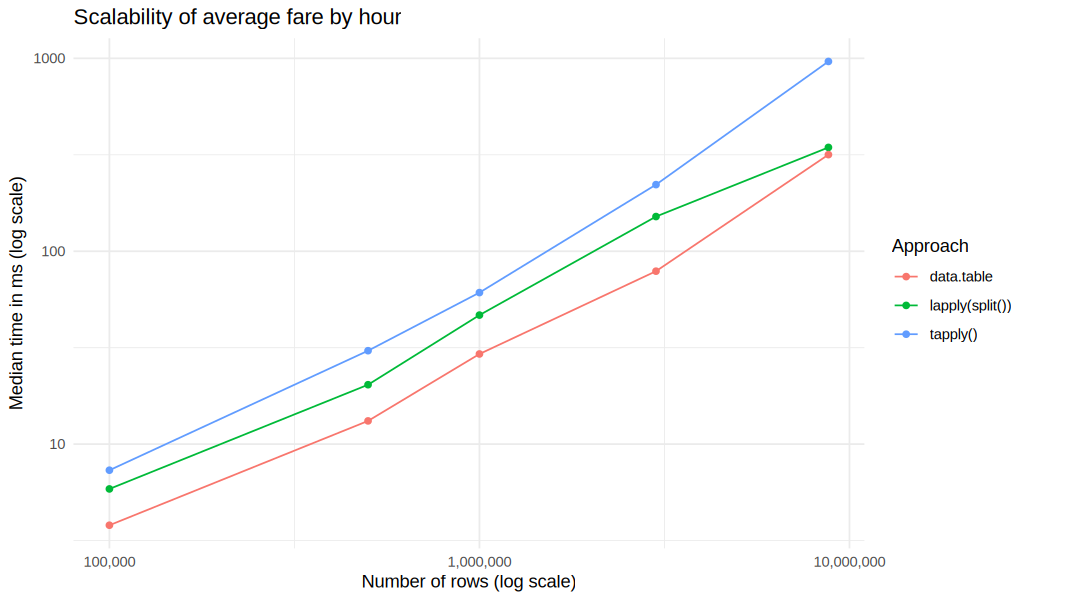

In [30]:
# scalability: how the time grows with the number of rows
sizes <- sort(unique(c(1e5, 5e5, 1e6, 3e6, nrow(trips))))
sizes <- sizes[sizes <= nrow(trips)]

scal <- rbindlist(lapply(sizes, function(n) {
  d_dt <- trips[sample(.N, n), .(hour, fare_amount)]
  d_df <- as.data.frame(d_dt)
  mb <- microbenchmark("tapply()" = grp_tapply(d_df),
                       "lapply(split())" = grp_lapply(d_df),
                       "data.table" = grp_dt(d_dt), times = 3)
  s <- as.data.table(summary(mb, unit = "ms"))
  data.table(rows = n, approach = as.character(s$expr), median_ms = s$median)
}))
scal

p_scal <- ggplot(scal, aes(x = rows, y = median_ms, colour = approach)) +
  geom_line() + geom_point() +
  scale_x_log10(labels = scales::comma) + scale_y_log10() +
  labs(title = "Scalability of average fare by hour", x = "Number of rows (log scale)",
       y = "Median time in ms (log scale)", colour = "Approach") +
  theme_minimal()
print(p_scal)

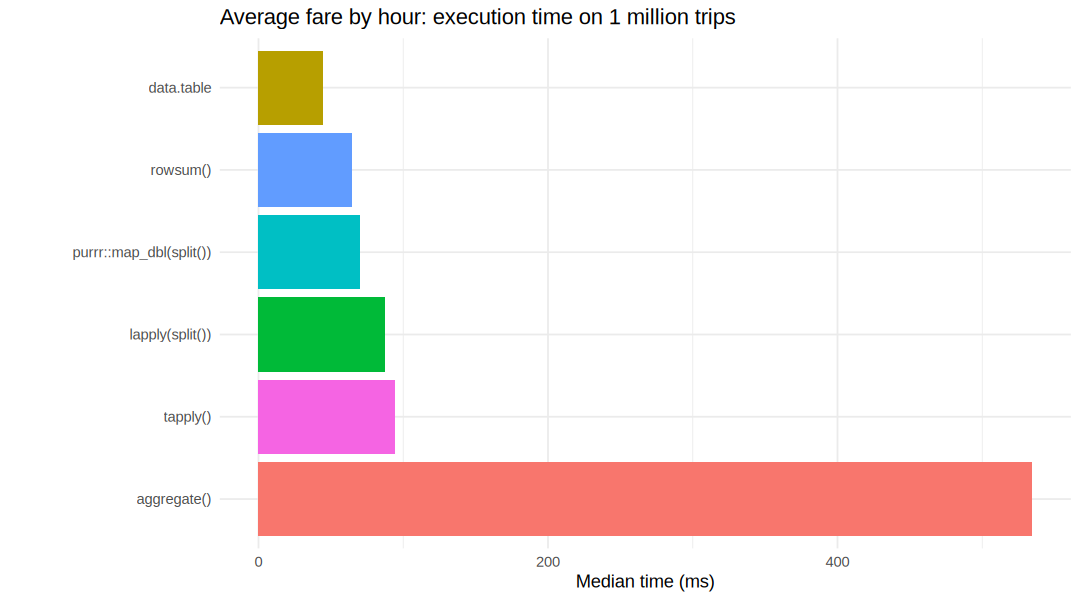

In [31]:
p_bench <- ggplot(bench_all[Comparison == "Average fare by hour (1M rows)"],
                  aes(x = reorder(Approach, -Median_ms), y = Median_ms, fill = Approach)) +
  geom_col(show.legend = FALSE) + coord_flip() +
  labs(title = "Average fare by hour: execution time on 1 million trips", x = NULL, y = "Median time (ms)") +
  theme_minimal()
print(p_bench)

**Task 6: Data visualization**

Each plot is followed by one or two lines of interpretation written from the numbers.

Demand is lowest at hour 4 and peaks at hour 18 with 629,363 trips.


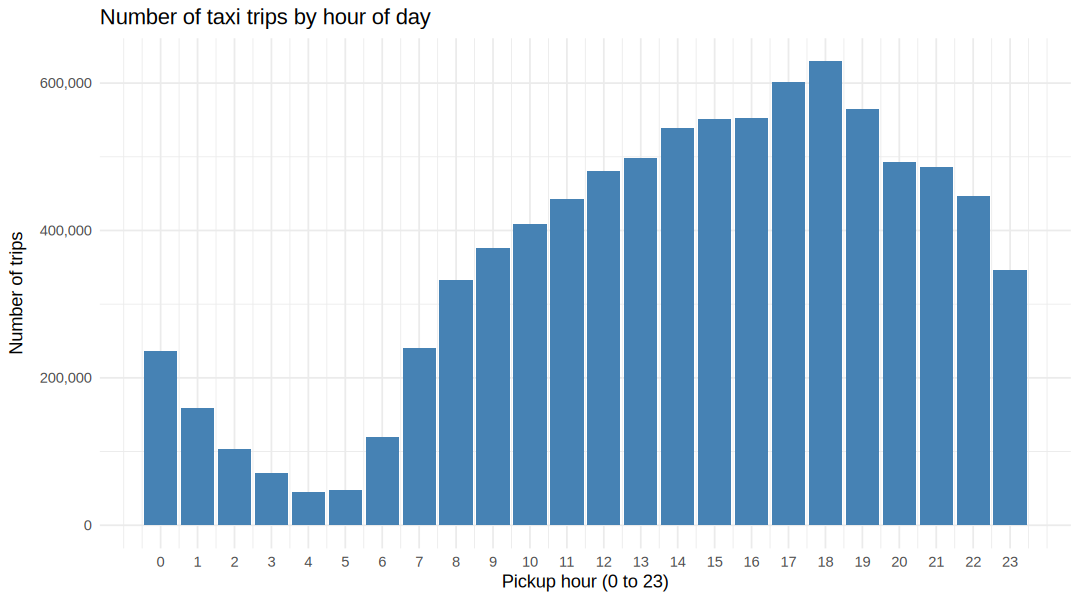

In [32]:
p1 <- ggplot(by_hour, aes(x = hour, y = trips)) +
  geom_col(fill = "steelblue") +
  scale_x_continuous(breaks = 0:23) + scale_y_continuous(labels = scales::comma) +
  labs(title = "Number of taxi trips by hour of day", x = "Pickup hour (0 to 23)", y = "Number of trips") +
  theme_minimal()
print(p1)
cat("Demand is lowest at hour", qt$hour, "and peaks at hour", pk$hour, "with", format(pk$trips, big.mark = ","), "trips.\n")

Busiest day is Thu and quietest is Mon 


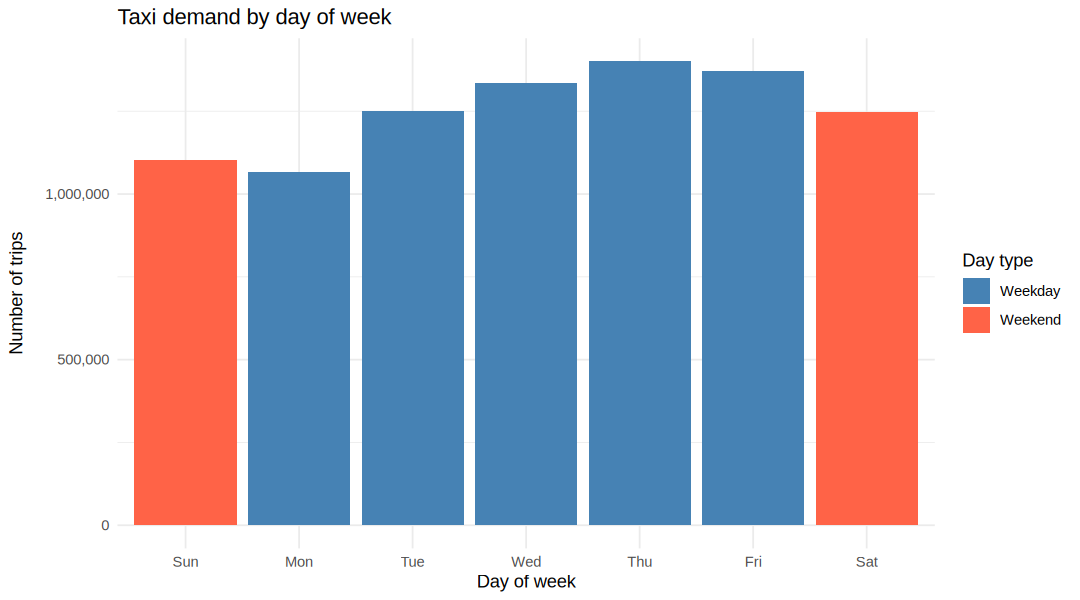

In [33]:
by_wday[, day_type := ifelse(wday %in% c("Sat", "Sun"), "Weekend", "Weekday")]
p2 <- ggplot(by_wday, aes(x = wday, y = trips, fill = day_type)) +
  geom_col() +
  scale_y_continuous(labels = scales::comma) +
  scale_fill_manual(values = c(Weekday = "steelblue", Weekend = "tomato")) +
  labs(title = "Taxi demand by day of week", x = "Day of week", y = "Number of trips", fill = "Day type") +
  theme_minimal()
print(p2)
cat("Busiest day is", as.character(by_wday[which.max(trips), wday]), "and quietest is", as.character(by_wday[which.min(trips), wday]), "\n")

Trip counts by month: Jan 2,872,830 | Feb 2,721,823 | Mar 3,177,312 


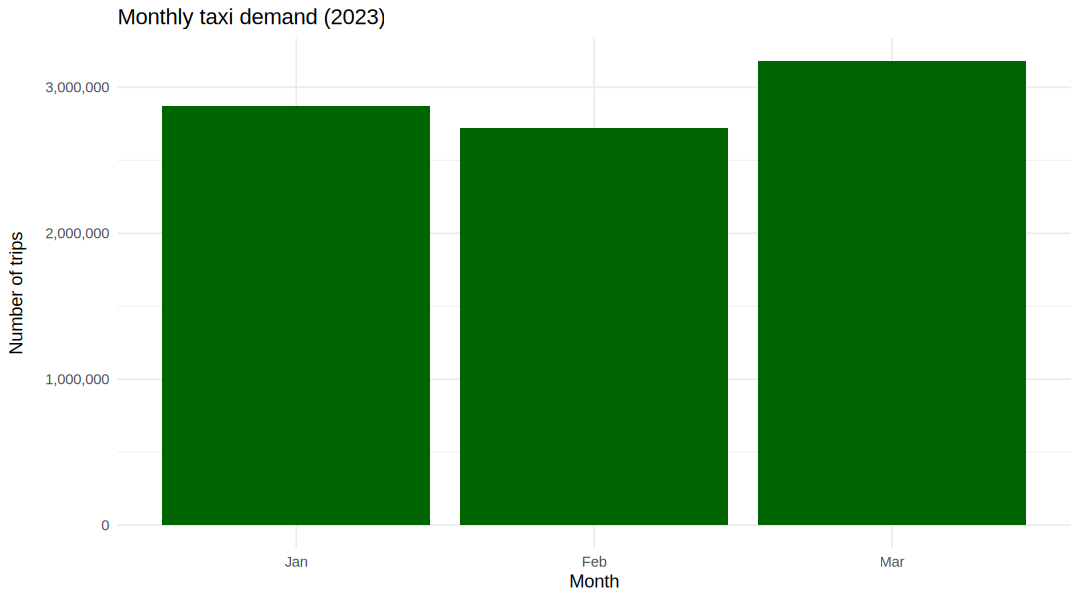

In [34]:
by_month[, month_lab := factor(month, levels = 1:12, labels = month.abb)]
p3 <- ggplot(by_month, aes(x = month_lab, y = trips)) +
  geom_col(fill = "darkgreen") +
  scale_y_continuous(labels = scales::comma) +
  labs(title = "Monthly taxi demand (2023)", x = "Month", y = "Number of trips") +
  theme_minimal()
print(p3)
cat("Trip counts by month:", paste(by_month$month_lab, format(by_month$trips, big.mark = ","), collapse = " | "), "\n")

Average fare is highest at hour 5 ( 27.01 USD ) and lowest at hour 2 ( 16.7 USD ).


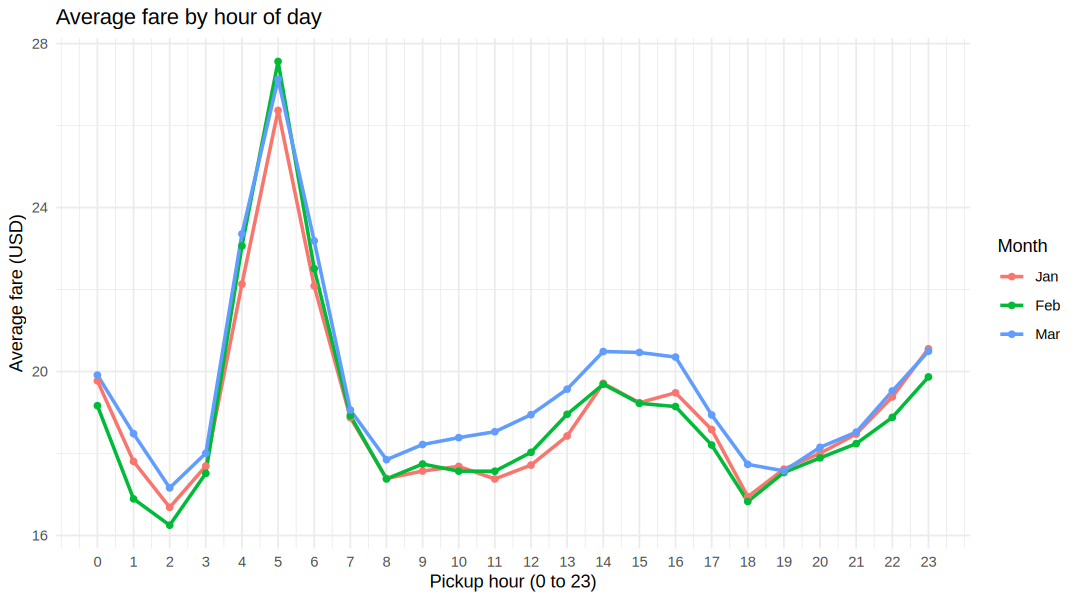

In [35]:
fare_hm <- trips[, .(avg_fare = mean(fare_amount)), by = .(month_lab = factor(month, levels = 1:12, labels = month.abb), hour)]
p4 <- ggplot(fare_hm, aes(x = hour, y = avg_fare, colour = month_lab)) +
  geom_line(linewidth = 1) + geom_point() +
  scale_x_continuous(breaks = 0:23) +
  labs(title = "Average fare by hour of day", x = "Pickup hour (0 to 23)", y = "Average fare (USD)", colour = "Month") +
  theme_minimal()
print(p4)
cat("Average fare is highest at hour", by_hour[which.max(avg_fare), hour], "(", round(by_hour[which.max(avg_fare), avg_fare], 2), "USD ) and lowest at hour", by_hour[which.min(avg_fare), hour], "(", round(by_hour[which.min(avg_fare), avg_fare], 2), "USD ).\n")

Best revenue day: 2023-03-16 with 3,386,968 USD; weakest day: 2023-01-02 with 1,933,796 USD


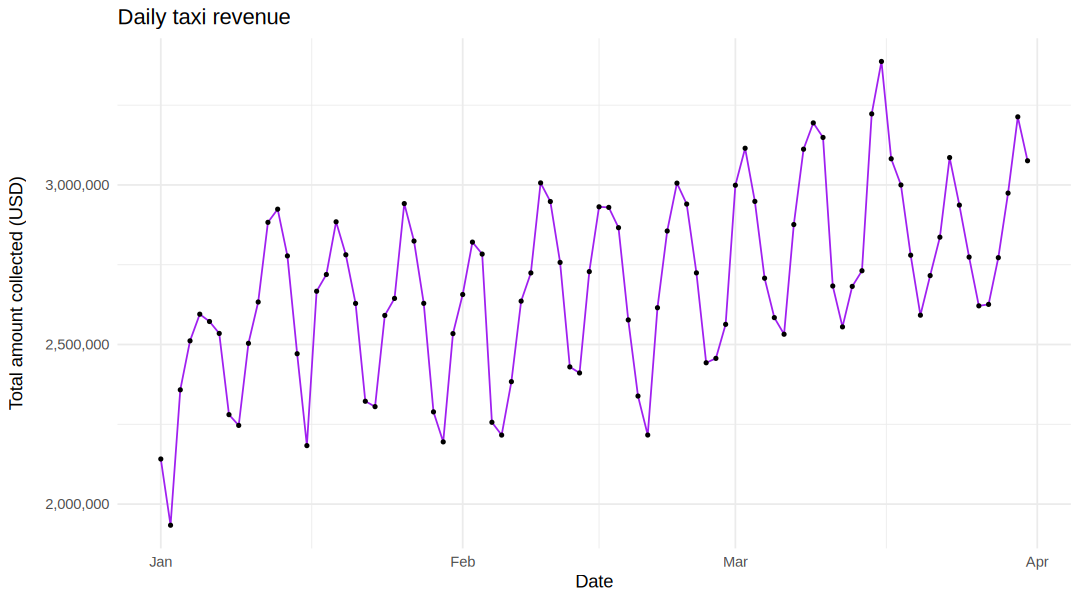

In [36]:
daily <- trips[, .(revenue = sum(total_amount), trips = .N), by = .(month, day)]
daily[, date := as.Date(sprintf("2023-%02d-%02d", month, day))]
setorder(daily, date)
p5 <- ggplot(daily, aes(x = date, y = revenue)) +
  geom_line(colour = "purple") + geom_point(size = 0.8) +
  scale_y_continuous(labels = scales::comma) +
  labs(title = "Daily taxi revenue", x = "Date", y = "Total amount collected (USD)") +
  theme_minimal()
print(p5)
cat("Best revenue day:", format(daily[which.max(revenue), date]), "with", format(round(daily[which.max(revenue), revenue]), big.mark = ","), "USD; weakest day:", format(daily[which.min(revenue), date]), "with", format(round(daily[which.min(revenue), revenue]), big.mark = ","), "USD\n")

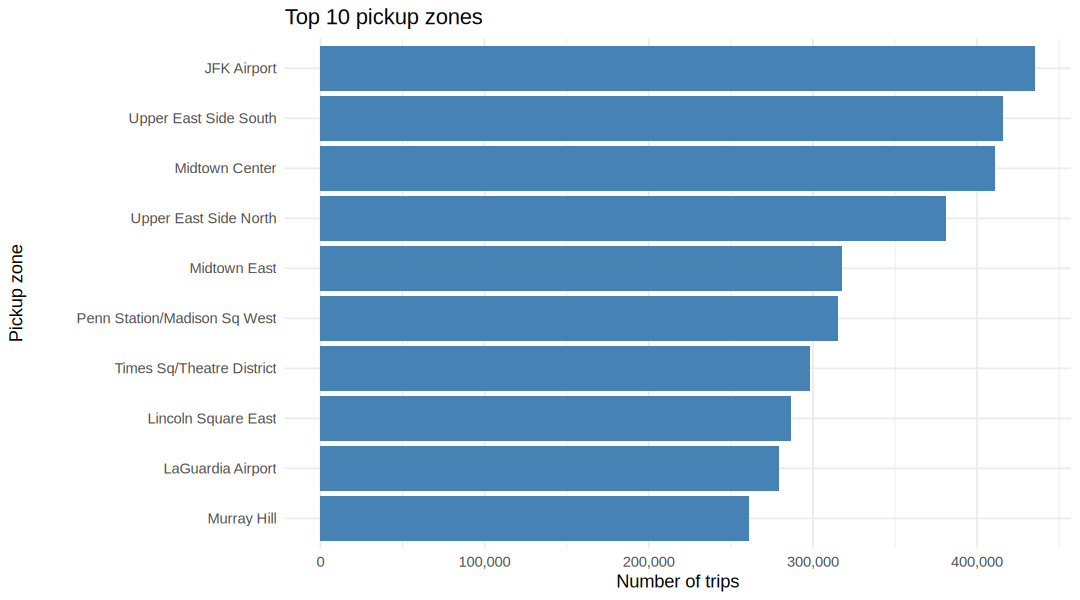

Top pickup zone: JFK Airport | top drop-off zone: Upper East Side North 


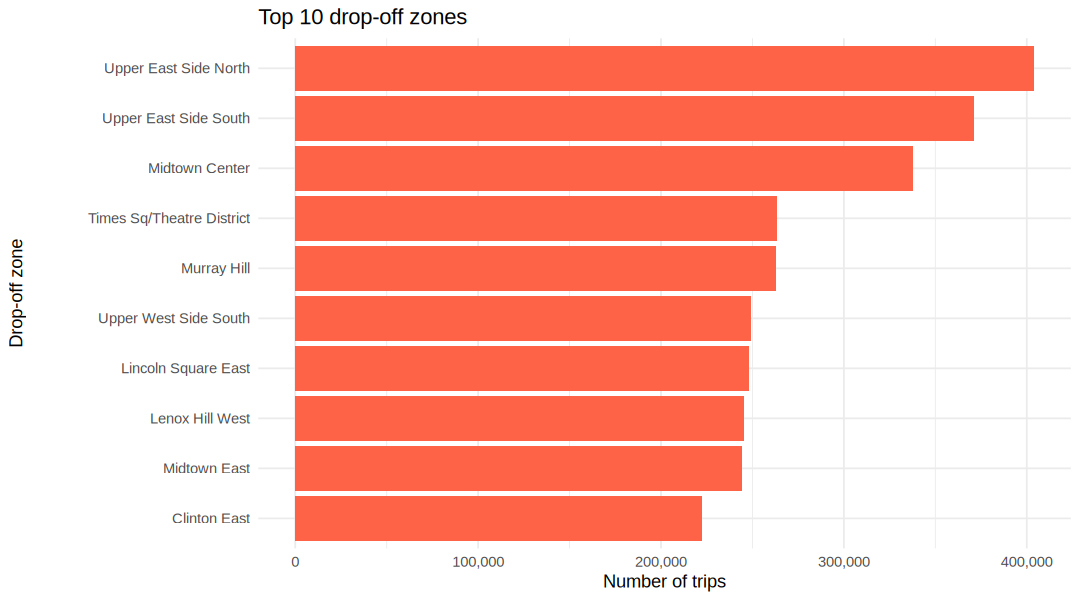

In [37]:
top_pu <- trips[!is.na(PU_zone), .N, by = PU_zone][order(-N)][1:10]
p6 <- ggplot(top_pu, aes(x = reorder(PU_zone, N), y = N)) +
  geom_col(fill = "steelblue") + coord_flip() +
  scale_y_continuous(labels = scales::comma) +
  labs(title = "Top 10 pickup zones", x = "Pickup zone", y = "Number of trips") +
  theme_minimal()
print(p6)

top_do <- trips[!is.na(DO_zone), .N, by = DO_zone][order(-N)][1:10]
p7 <- ggplot(top_do, aes(x = reorder(DO_zone, N), y = N)) +
  geom_col(fill = "tomato") + coord_flip() +
  scale_y_continuous(labels = scales::comma) +
  labs(title = "Top 10 drop-off zones", x = "Drop-off zone", y = "Number of trips") +
  theme_minimal()
print(p7)
cat("Top pickup zone:", top_pu$PU_zone[1], "| top drop-off zone:", top_do$DO_zone[1], "\n")

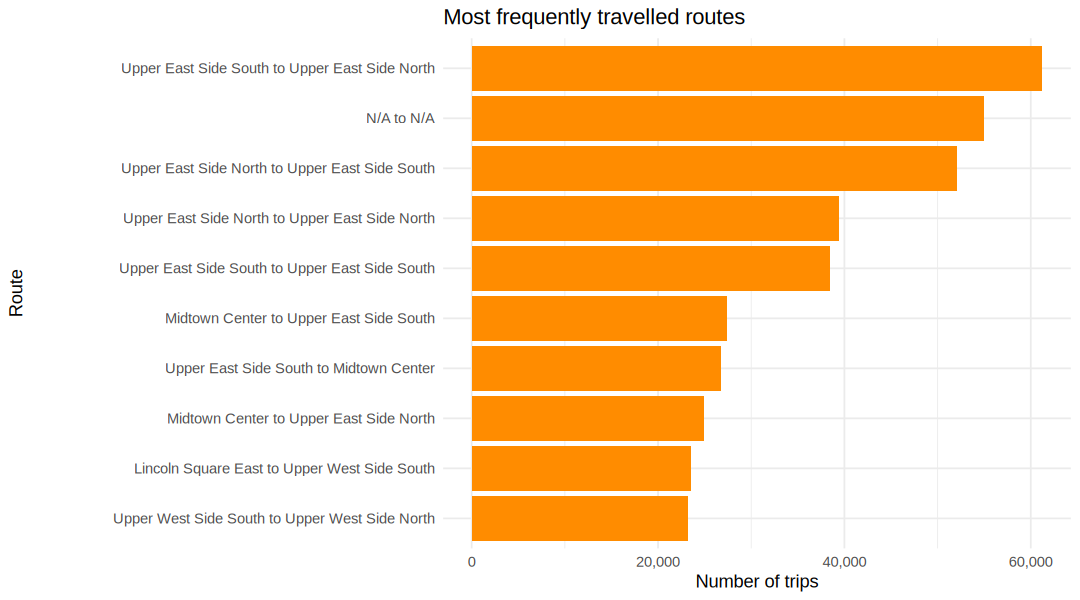

The busiest route and the highest revenue route are different, so frequent does not always mean most profitable. 


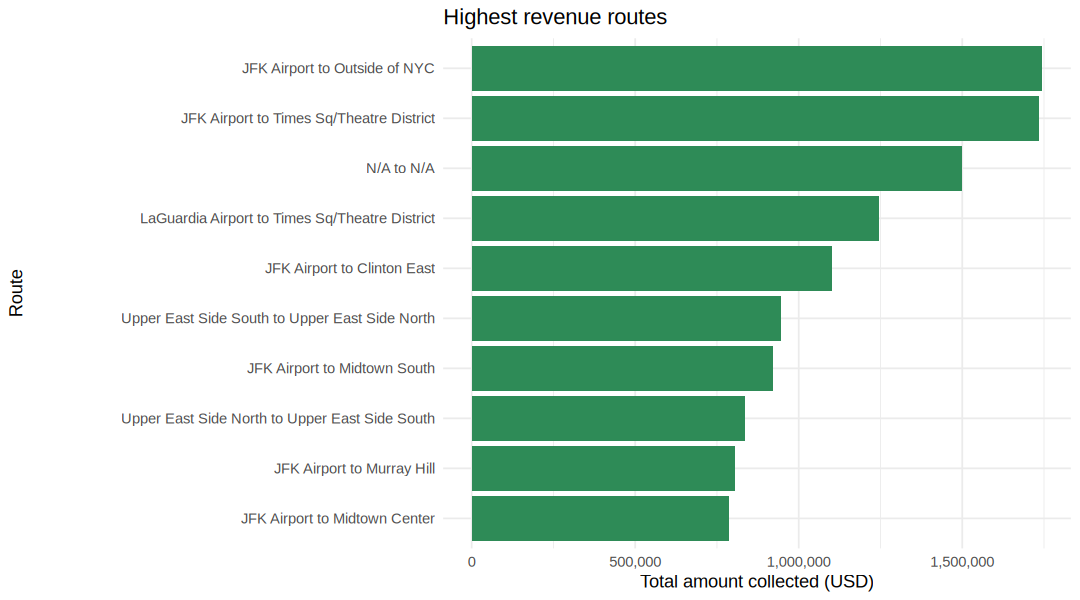

In [38]:
top_routes_count[, route := paste(PU_zone, "to", DO_zone)]
p8 <- ggplot(top_routes_count, aes(x = reorder(route, trips), y = trips)) +
  geom_col(fill = "darkorange") + coord_flip() +
  scale_y_continuous(labels = scales::comma) +
  labs(title = "Most frequently travelled routes", x = "Route", y = "Number of trips") +
  theme_minimal()
print(p8)

top_routes_revenue[, route := paste(PU_zone, "to", DO_zone)]
p9 <- ggplot(top_routes_revenue, aes(x = reorder(route, revenue), y = revenue)) +
  geom_col(fill = "seagreen") + coord_flip() +
  scale_y_continuous(labels = scales::comma) +
  labs(title = "Highest revenue routes", x = "Route", y = "Total amount collected (USD)") +
  theme_minimal()
print(p9)
cat("The busiest route and the highest revenue route are", ifelse(top_routes_count$route[1] == top_routes_revenue$route[1], "the same.", "different, so frequent does not always mean most profitable."), "\n")

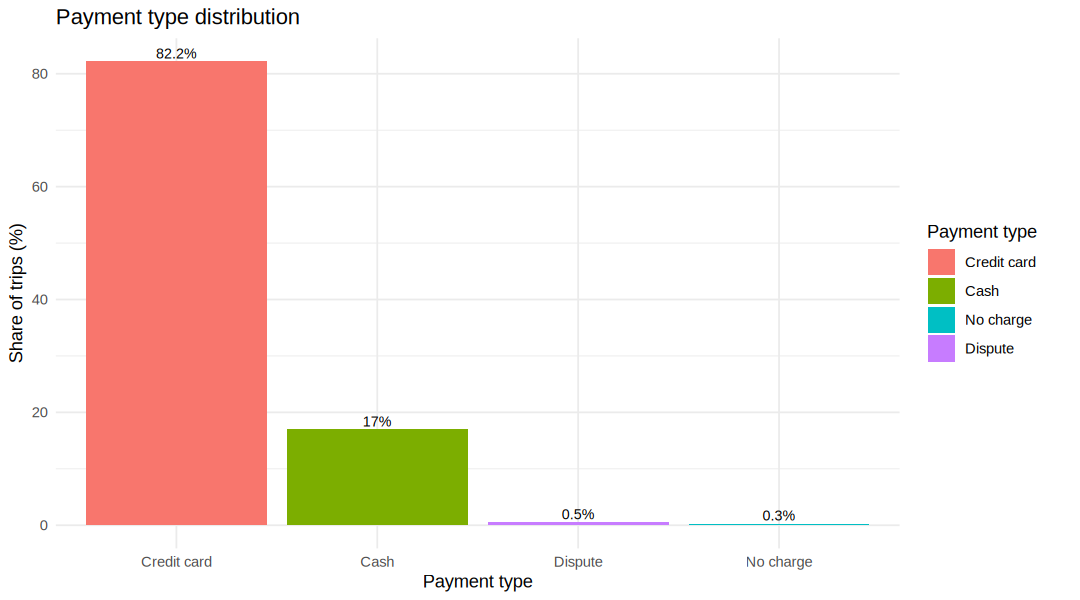

Most used payment type: Credit card with 82.2 % of trips.


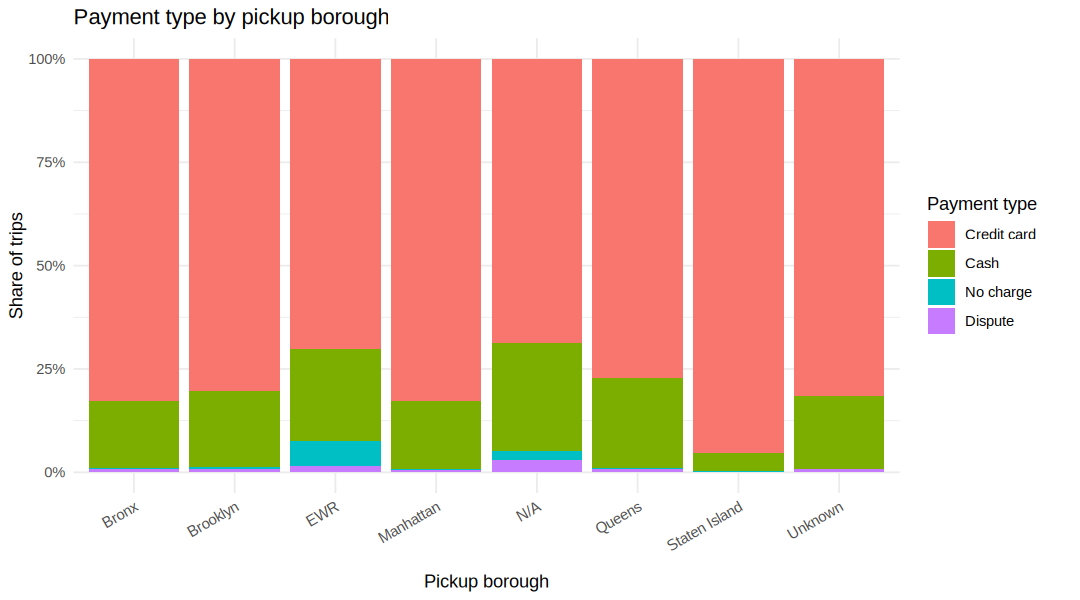

In [39]:
pay_share <- trips[, .N, by = payment][, share := 100 * N / sum(N)][order(-N)]
p10 <- ggplot(pay_share, aes(x = reorder(payment, -share), y = share, fill = payment)) +
  geom_col() +
  geom_text(aes(label = paste0(round(share, 1), "%")), vjust = -0.3, size = 3) +
  labs(title = "Payment type distribution", x = "Payment type", y = "Share of trips (%)", fill = "Payment type") +
  theme_minimal()
print(p10)

p10b <- ggplot(pay_borough, aes(x = PU_borough, y = N, fill = payment)) +
  geom_col(position = "fill") +
  scale_y_continuous(labels = scales::percent) +
  labs(title = "Payment type by pickup borough", x = "Pickup borough", y = "Share of trips", fill = "Payment type") +
  theme_minimal() + theme(axis.text.x = element_text(angle = 30, hjust = 1))
print(p10b)
cat("Most used payment type:", as.character(pay_share$payment[1]), "with", round(pay_share$share[1], 1), "% of trips.\n")

Correlation between distance and fare is 0.963 which is a strong positive relationship, so fare grows close to linearly with distance. The spread around the line comes from waiting time in traffic, surcharges and tolls. 


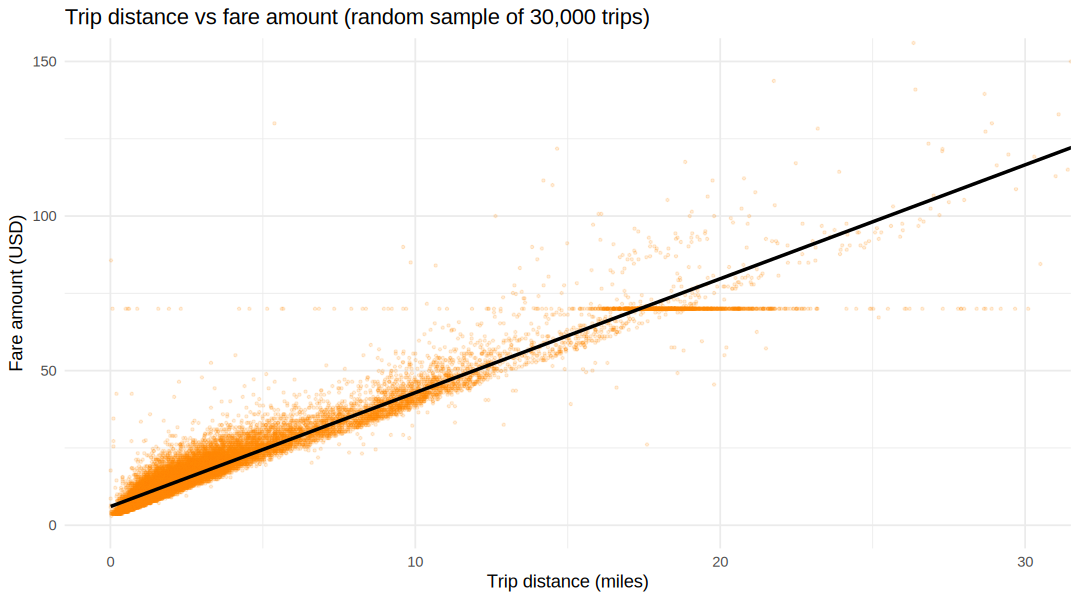

In [40]:
plot_smp <- trips[sample(.N, min(.N, 30000)), .(trip_distance, fare_amount)]
p11 <- ggplot(plot_smp, aes(x = trip_distance, y = fare_amount)) +
  geom_point(alpha = 0.15, size = 0.6, colour = "darkorange") +
  geom_smooth(method = "lm", formula = y ~ x, colour = "black") +
  coord_cartesian(xlim = c(0, 30), ylim = c(0, 150)) +
  labs(title = "Trip distance vs fare amount (random sample of 30,000 trips)",
       x = "Trip distance (miles)", y = "Fare amount (USD)") +
  theme_minimal()
print(p11)
cat("Correlation between distance and fare is", round(cor_fd, 3), "which is", ifelse(cor_fd > 0.8, "a strong positive relationship, so fare grows close to linearly with distance. The spread around the line comes from waiting time in traffic, surcharges and tolls.", "a positive but weaker relationship, so time in traffic, tolls and surcharges matter a lot too."), "\n")

**Optional: interactive map with leaflet**

The lookup table has no coordinates, so this map is at borough level (approximate borough centre points) with the three airports marked. It needs the leaflet package and shows only in the notebook, not in the exported PDF. For the PDF I take a screenshot of the map.

In [41]:
if (!requireNamespace("leaflet", quietly = TRUE)) install.packages("leaflet")
if (requireNamespace("leaflet", quietly = TRUE)) {
  library(leaflet)
  boro_xy <- data.table(PU_borough = c("Manhattan", "Brooklyn", "Queens", "Bronx", "Staten Island", "EWR"),
                        lat = c(40.7831, 40.6782, 40.7282, 40.8448, 40.5795, 40.6895),
                        lng = c(-73.9712, -73.9442, -73.7949, -73.8648, -74.1502, -74.1745))
  boro_stats <- trips[, .(trips = .N, revenue = sum(total_amount), avg_fare = mean(fare_amount)), by = PU_borough]
  boro_map <- merge(boro_stats, boro_xy, by = "PU_borough")

  airports <- data.table(PU_zone = c("JFK Airport", "LaGuardia Airport", "Newark Airport"),
                         lat = c(40.6413, 40.7769, 40.6895), lng = c(-73.7781, -73.8740, -74.1745))
  ap_stats <- merge(trips[PU_zone %in% airports$PU_zone, .(trips = .N, revenue = sum(total_amount), avg_fare = mean(fare_amount)), by = PU_zone],
                    airports, by = "PU_zone")

  leaflet() %>%
    addTiles() %>%
    addCircleMarkers(data = boro_map, lng = ~lng, lat = ~lat, radius = ~ 8 + 30 * trips / max(trips),
                     color = "steelblue", fillOpacity = 0.6,
                     popup = ~ paste0("<b>", PU_borough, "</b><br>Pickups: ", format(trips, big.mark = ","),
                                      "<br>Revenue: $", format(round(revenue), big.mark = ","),
                                      "<br>Avg fare: $", round(avg_fare, 2))) %>%
    addCircleMarkers(data = ap_stats, lng = ~lng, lat = ~lat, radius = 8, color = "tomato", fillOpacity = 0.8,
                     popup = ~ paste0("<b>", PU_zone, "</b><br>Pickups: ", format(trips, big.mark = ","),
                                      "<br>Revenue: $", format(round(revenue), big.mark = ","),
                                      "<br>Avg fare: $", round(avg_fare, 2)))
}

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘proxy’, ‘e1071’, ‘wk’, ‘lazyeval’, ‘sp’, ‘terra’, ‘classInt’, ‘s2’, ‘units’, ‘crosstalk’, ‘leaflet.providers’, ‘png’, ‘raster’, ‘sf’


Warning message in install.packages("leaflet"):
“installation of package ‘s2’ had non-zero exit status”
Warning message in install.packages("leaflet"):
“installation of package ‘raster’ had non-zero exit status”
Warning message in install.packages("leaflet"):
“installation of package ‘sf’ had non-zero exit status”
Warning message in install.packages("leaflet"):
“installation of package ‘leaflet’ had non-zero exit status”


**Task 7: Critical analysis and recommendation**

The numbers quoted below are printed by code from the benchmark table, so they always match my own run.

In [42]:
get_ms <- function(comp, app) bench_all[Comparison == comp & Approach == app, Median_ms]
g <- "Average fare by hour (1M rows)"; r_ <- "Row-wise fare per mile (100k rows)"; j <- "Join with zone table (1M rows)"
par_name <- paste0("Parallel (foreach %dopar%, ", n_workers, " workers)")

cat("Q1. Fastest approach in each comparison:\n")
print(bench_all[, .SD[which.min(Median_ms)], by = Comparison][, .(Comparison, Fastest = Approach, Median_ms)])

cat("\nQ2. Group average on 1M rows: aggregate() took", get_ms(g, "aggregate()"), "ms, tapply() took", get_ms(g, "tapply()"),
    "ms, data.table took", get_ms(g, "data.table"), "ms.\n")
cat("    Join on 1M rows: merge() took", get_ms(j, "merge() base R"), "ms, data.table took", get_ms(j, "data.table join"), "ms.\n")

cat("\nQ3 and Q4. Row-wise fare per mile on 100k rows: apply()", get_ms(r_, "apply()"), "ms, lapply()", get_ms(r_, "lapply()"),
    "ms, purrr::map2_dbl()", get_ms(r_, "purrr::map2_dbl()"), "ms, vectorized", get_ms(r_, "vectorized"), "ms, data.table", get_ms(r_, "data.table"), "ms.\n")

cat("\nQ5. Heavy job: sequential", round(t_seq, 2), "sec, parallel with", n_workers, "workers", round(t_par, 2), "sec, speedup", round(speedup, 2), "\n")
cat("    ->", ifelse(speedup > 1.2, "parallel gave a real gain on this job.", "parallel gave little or no gain on this job."), "\n")

sp_light <- t_seq_light / t_par_light
cat("\nQ6. Light job: sequential", round(t_seq_light, 3), "sec, parallel", round(t_par_light, 3), "sec, speedup", round(sp_light, 2), "\n")
cat("    ->", ifelse(sp_light < 1, "parallel was slower here, so parallel is not always faster. The overhead of starting workers and sending data was bigger than the work.",
                     "parallel was not slower here, but the gain is tiny compared with the heavy job, because the work per task is small."), "\n")

Q1. Fastest approach in each comparison:
                            Comparison                               Fastest
                                <char>                                <char>
1:  Row-wise fare per mile (100k rows)                            vectorized
2:      Average fare by hour (1M rows)                            data.table
3:      Join with zone table (1M rows)                       data.table join
4: Bootstrap job on 3 month partitions Parallel (foreach %dopar%, 2 workers)
5:     Light job on 3 month partitions             Sequential (foreach %do%)
   Median_ms
       <num>
1:     0.229
2:    44.794
3:    71.872
4: 46984.000
5:    40.000

Q2. Group average on 1M rows: aggregate() took 534.479 ms, tapply() took 94.216 ms, data.table took 44.794 ms.
    Join on 1M rows: merge() took 1971.627 ms, data.table took 71.872 ms.

Q3 and Q4. Row-wise fare per mile on 100k rows: apply() 776.954 ms, lapply() 485.182 ms, purrr::map2_dbl() 165.06 ms, vectorized 0.229 ms, dat

**Answers**

**2. How does data.table improve the processing of large datasets?** It does the grouping, joining and sorting in compiled C code with radix ordering and several threads, it computes common summaries like mean and sum per group internally, it adds or changes columns by reference so the table is not copied, and one compact syntax (DT[i, j, by]) covers filter, select, group and join. Less copying also means less memory.

**3. When is functional programming preferable?** When there is no ready made vectorized function and each element needs its own custom logic, when looping over files, models or partitions (like the month partitions above), and when the code reads better as map over a list. The cost is a function call per element, so it should not be used for simple arithmetic on millions of rows.

**4. When do vectorized operations provide better performance?** For element wise calculations on whole columns (fare divided by distance, unit conversions, comparisons). The loop runs in compiled code, so it is much faster than apply or lapply and uses little extra memory.

**7. Trade-offs.** apply and lapply are easy to write but slow and sometimes memory hungry. Vectorized code is fast and simple but only fits element wise maths. data.table is fast and memory efficient but has its own syntax that has to be learnt, and update by reference can surprise people used to copy on modify. Parallel code can cut the time of heavy independent jobs but adds setup code, uses more total memory because data is copied to workers, and can be slower for small jobs.

**8. Recommendation.** For large scale analytics in R I would use data.table for loading, cleaning, joining and aggregating, vectorized expressions inside it for column calculations, purrr or lapply only for looping over big independent units like partitions, and foreach with doParallel only for heavy independent jobs where the per task time is large compared with the cost of moving data. The verdict cell below checks this against my own numbers.

In [43]:
fast_grp <- bench_all[Comparison == g][which.min(Median_ms), Approach]
fast_join <- bench_all[Comparison == j][which.min(Median_ms), Approach]
cat("Fastest for grouping:", fast_grp, "| fastest for joining:", fast_join, "\n")
if (fast_grp == "data.table" && fast_join == "data.table join") {
  cat("The benchmarks support the recommendation: data.table was fastest for both grouping and joining.\n")
} else {
  cat("In this run data.table was not the fastest in every comparison, so the recommendation should be read together with the memory and readability columns of the table.\n")
}
cat("Parallel speedup on the heavy job was", round(speedup, 2), "with", n_workers, "workers and", round(sp_light, 2), "on the light job.\n")

Fastest for grouping: data.table | fastest for joining: data.table join 
The benchmarks support the recommendation: data.table was fastest for both grouping and joining.
Parallel speedup on the heavy job was 1.1 with 2 workers and 0.05 on the light job.


**Conclusion**

The same results can be produced in many ways in R, but the time and memory they need are very different once the data has millions of rows. Row by row functional code is the slowest, vectorized code is best for element wise work, and data.table is the best all round tool for filtering, joining and grouping. Parallel processing helped only when each partition had a lot of computation to do, and it did not reach the ideal speedup because of the cost of starting workers and moving data, the small number of partitions and the limited number of cores. The workflow of cleaning, joining, analysing, benchmarking and visualising is one pipeline that scales to larger months of data without changing the code.